In [1]:
#Cell 1 — Import Libraries

In [2]:
import os
pass # removed hardcoded chdir
print('Working directory:', os.getcwd())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print('All libraries imported successfully!')

Working directory: C:\Users\user\OneDrive\Desktop\FUTURE_ML_01(Sales & Demand Forecasting for Businesses)


All libraries imported successfully!


In [3]:
# Cell 2 — Load Dataset

In [4]:
df = pd.read_csv('train.csv')
print('Shape:', df.shape)
print('\n Columns:', df.columns.tolist())
df.head()

Shape: (9800, 18)

 Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [5]:
# Cell 3 — Basic Info

In [6]:
print(' Sales Statistics:')
print(df[['Sales']].describe())
print('\n Missing Values:')
print(df.isnull().sum())

 Sales Statistics:
              Sales
count   9800.000000
mean     230.769059
std      626.651875
min        0.444000
25%       17.248000
50%       54.490000
75%      210.605000
max    22638.480000

 Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [7]:
# Cell 4 — Data Cleaning

In [8]:
# Parse dates (DD/MM/YYYY format)
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  dayfirst=True)

# Drop missing Sales & duplicates
df.dropna(subset=['Sales'], inplace=True)
df.drop_duplicates(inplace=True)
df.sort_values('Order Date', inplace=True)
df.reset_index(drop=True, inplace=True)

print(' Cleaned dataset shape:', df.shape)
print(' Date range:', df['Order Date'].min().date(), '→', df['Order Date'].max().date())
print(' Total Sales: $', round(df['Sales'].sum(), 2))

 Cleaned dataset shape: (9800, 18)
 Date range: 2015-01-03 → 2018-12-30
 Total Sales: $ 2261536.78


In [9]:
# Cell 5 — Feature Engineering

In [10]:
# Order-level temporal features
df['Year']       = df['Order Date'].dt.year
df['Month']      = df['Order Date'].dt.month
df['Quarter']    = df['Order Date'].dt.quarter
df['DayOfWeek']  = df['Order Date'].dt.dayofweek
df['WeekOfYear'] = df['Order Date'].dt.isocalendar().week.astype(int)
df['DayOfYear']  = df['Order Date'].dt.dayofyear
df['IsWeekend']  = (df['DayOfWeek'] >= 5).astype(int)
df['ShipDays']   = (df['Ship Date'] - df['Order Date']).dt.days

# Monthly aggregated time-series
monthly = df.groupby(['Year', 'Month'])['Sales'].sum().reset_index()
monthly['Date'] = pd.to_datetime(monthly[['Year', 'Month']].assign(Day=1))
monthly.sort_values('Date', inplace=True)
monthly.reset_index(drop=True, inplace=True)

# Rolling & lag features
monthly['Rolling_3M'] = monthly['Sales'].rolling(3).mean()
monthly['Rolling_6M'] = monthly['Sales'].rolling(6).mean()
monthly['Lag_1M']     = monthly['Sales'].shift(1)
monthly['Lag_3M']     = monthly['Sales'].shift(3)
monthly['MonthNum']   = range(len(monthly))

print(' feature engineering complete!')
monthly.tail(8)

 feature engineering complete!


,Year,Month,Sales,Date,Rolling_3M,Rolling_6M,Lag_1M,Lag_3M,MonthNum
40,2018,5,43825.9822,2018-05-01,46077.101700,49561.316250,35541.9101,19920.9974,40
41,2018,6,48190.7277,2018-06-01,42519.540000,41636.584033,43825.9822,58863.4128,41
42,2018,7,44825.1040,2018-07-01,45613.937967,41861.355700,48190.7277,35541.9101,42
43,2018,8,62837.8480,2018-08-01,51951.226567,49014.164133,44825.1040,43825.9822,43
44,2018,9,86152.8880,2018-09-01,64605.280000,53562.410000,62837.8480,48190.7277,44
45,2018,10,77448.1312,2018-10-01,75479.622400,60546.780183,86152.8880,44825.1040,45
46,2018,11,117938.1550,2018-11-01,93846.391400,72898.808983,77448.1312,62837.8480,46
47,2018,12,83030.3888,2018-12-01,92805.558333,78705.419167,117938.1550,86152.8880,47


In [11]:
# Cell 6 — EDA Overview Charts

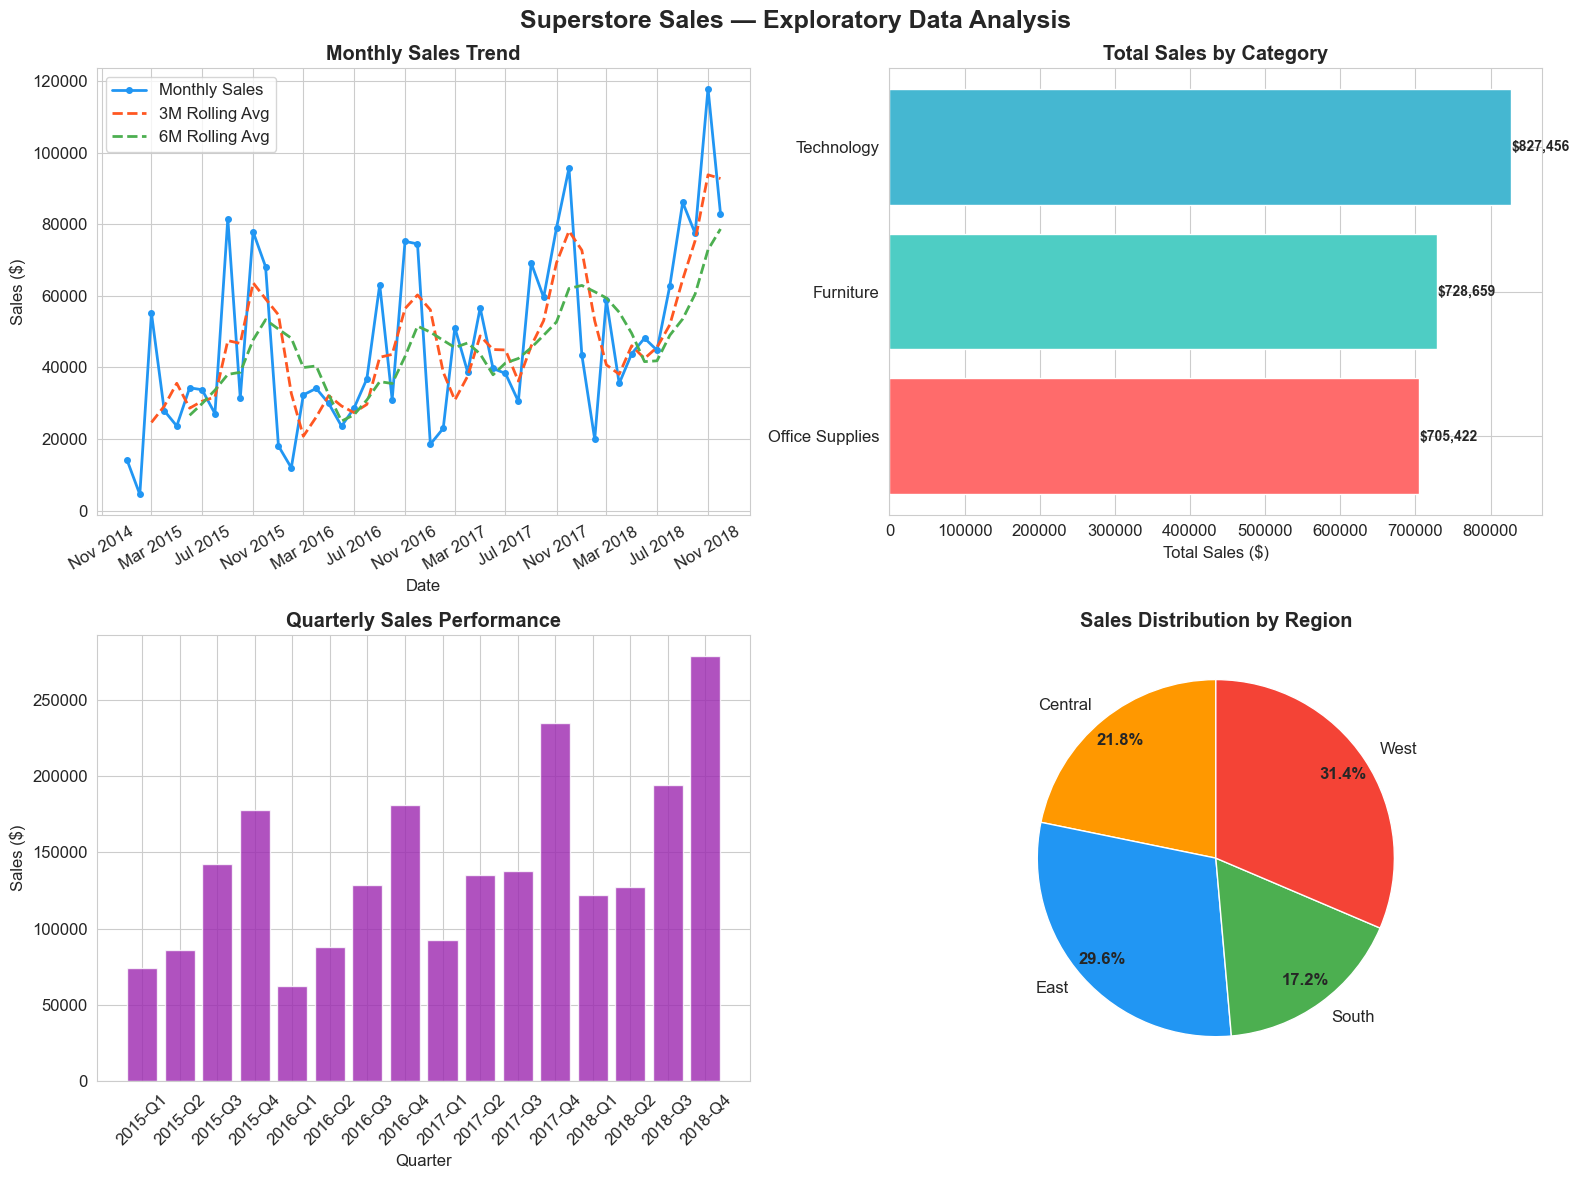

 EDA chart saved!


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(' Superstore Sales — Exploratory Data Analysis', fontsize=18, fontweight='bold')

# 1. Monthly Sales Trend
ax = axes[0, 0]
ax.plot(monthly['Date'], monthly['Sales'], color='#2196F3', lw=2, marker='o', ms=4, label='Monthly Sales')
ax.plot(monthly['Date'], monthly['Rolling_3M'], color='#FF5722', lw=2, ls='--', label='3M Rolling Avg')
ax.plot(monthly['Date'], monthly['Rolling_6M'], color='#4CAF50', lw=2, ls='--', label='6M Rolling Avg')
ax.set_title('Monthly Sales Trend', fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Sales ($)')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30)

# 2. Sales by Category
ax = axes[0, 1]
cat_sales = df.groupby('Category')['Sales'].sum().sort_values()
bars = ax.barh(cat_sales.index, cat_sales.values, color=['#FF6B6B','#4ECDC4','#45B7D1'])
ax.set_title('Total Sales by Category', fontweight='bold')
ax.set_xlabel('Total Sales ($)')
for bar, val in zip(bars, cat_sales.values):
    ax.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
            f'${val:,.0f}', va='center', fontweight='bold', fontsize=10)

# 3. Quarterly Sales
ax = axes[1, 0]
quarterly = df.groupby(['Year', 'Quarter'])['Sales'].sum().reset_index()
quarterly['Period'] = quarterly['Year'].astype(str) + '-Q' + quarterly['Quarter'].astype(str)
ax.bar(quarterly['Period'], quarterly['Sales'], color='#9C27B0', alpha=0.8)
ax.set_title('Quarterly Sales Performance', fontweight='bold')
ax.set_xlabel('Quarter'); ax.set_ylabel('Sales ($)')
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

# 4. Sales by Region
ax = axes[1, 1]
region_sales = df.groupby('Region')['Sales'].sum()
wedges, texts, autotexts = ax.pie(region_sales.values, labels=region_sales.index,
    autopct='%1.1f%%', colors=['#FF9800','#2196F3','#4CAF50','#F44336'],
    startangle=90, pctdistance=0.85)
for t in autotexts: t.set_fontweight('bold')
ax.set_title('Sales Distribution by Region', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(' EDA chart saved!')

In [13]:
# Cell 7 — Sales Heatmap

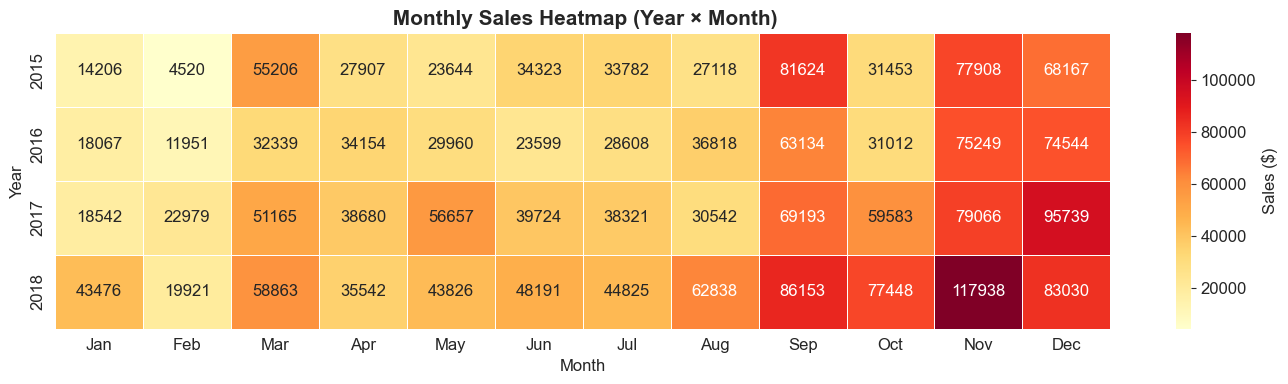

Heatmap saved!


In [14]:
pivot = df.groupby(['Year', 'Month'])['Sales'].sum().unstack()
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
pivot.columns = [month_names[m-1] for m in pivot.columns]

plt.figure(figsize=(14, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Sales ($)'})
plt.title(' Monthly Sales Heatmap (Year × Month)', fontsize=15, fontweight='bold')
plt.ylabel('Year'); plt.xlabel('Month')
plt.tight_layout()
plt.savefig('sales_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Heatmap saved!')

In [15]:
# Cell 8 — Prepare Features & Train/Test Split

In [16]:
le = LabelEncoder()
model_df = df.copy()
model_df['Category_enc']    = le.fit_transform(model_df['Category'])
model_df['Region_enc']      = le.fit_transform(model_df['Region'])
model_df['Segment_enc']     = le.fit_transform(model_df['Segment'])
model_df['SubCategory_enc'] = le.fit_transform(model_df['Sub-Category'])
model_df['ShipMode_enc']    = le.fit_transform(model_df['Ship Mode'])

features = ['Year','Month','Quarter','DayOfWeek','WeekOfYear','DayOfYear',
            'IsWeekend','ShipDays','Category_enc','Region_enc',
            'Segment_enc','SubCategory_enc','ShipMode_enc']

X = model_df[features]
y = model_df['Sales']

# Time-based split — 80% train, 20% test
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f' Training samples : {len(X_train)}')
print(f' Test samples     : {len(X_test)}')

 Training samples : 7840
 Test samples     : 1960


In [17]:
# Cell 9 — Train All 3 Models

In [18]:
models = {
    'Linear Regression':  LinearRegression(),
    'Random Forest':      RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting':  GradientBoostingRegressor(n_estimators=100, random_state=42, learning_rate=0.1),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    preds = np.clip(preds, 0, None)
    mae  = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2   = r2_score(y_test, preds)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'Predictions': preds}
    print(f' {name}')
    print(f'   MAE : ${mae:,.2f}  |  RMSE : ${rmse:,.2f}  |  R² : {r2:.4f}')
    print()

print(' All models trained!')

 Linear Regression
   MAE : $262.60  |  RMSE : $589.88  |  R² : 0.0022



 Random Forest
   MAE : $249.43  |  RMSE : $557.71  |  R² : 0.1080



 Gradient Boosting
   MAE : $217.15  |  RMSE : $529.81  |  R² : 0.1951

 All models trained!


In [19]:
# Cell 10 — Model Comparison Chart! 

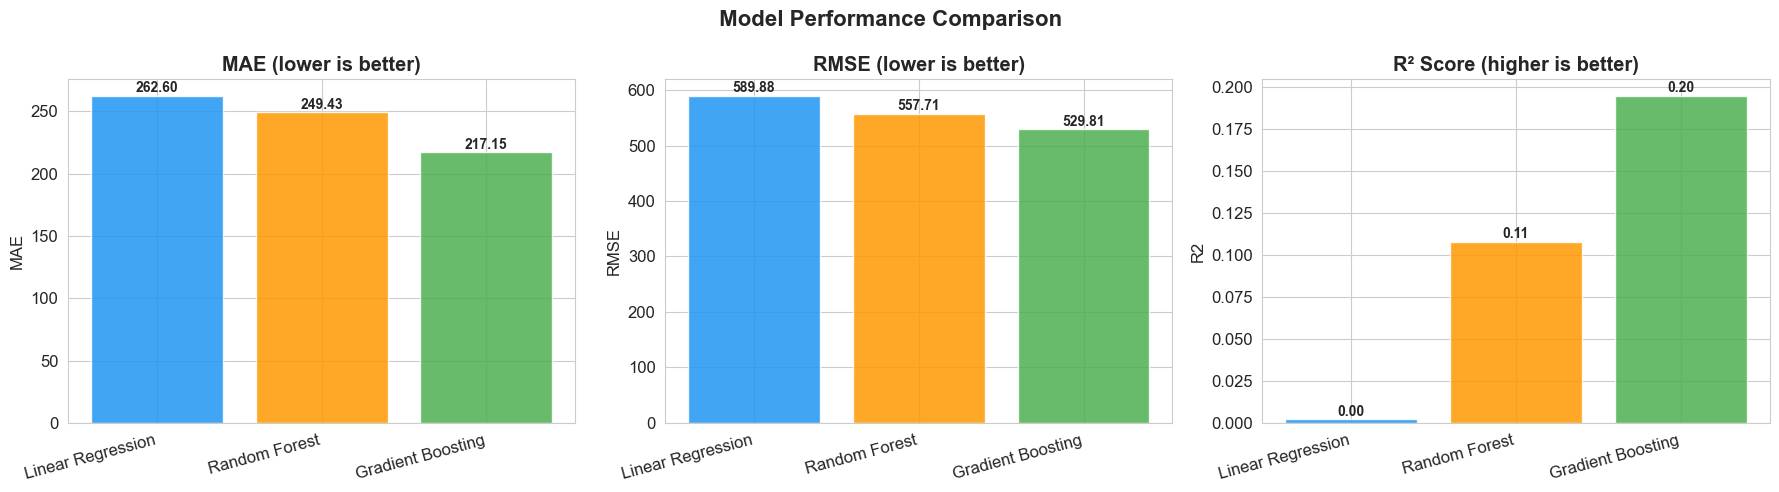

 Model comparison chart saved!


In [20]:
metrics_df = pd.DataFrame({
    k: {'MAE': v['MAE'], 'RMSE': v['RMSE'], 'R2': v['R2']}
    for k, v in results.items()
}).T.reset_index()
metrics_df.columns = ['Model', 'MAE', 'RMSE', 'R2']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(' Model Performance Comparison', fontsize=16, fontweight='bold')
colors = ['#2196F3', '#FF9800', '#4CAF50']

for ax, metric, title in zip(axes,
    ['MAE', 'RMSE', 'R2'],
    ['MAE (lower is better)', 'RMSE (lower is better)', 'R² Score (higher is better)']):
    bars = ax.bar(metrics_df['Model'], metrics_df[metric], color=colors, alpha=0.85)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(metric)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=15, ha='right')
    for bar, val in zip(bars, metrics_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(metrics_df[metric]) * 0.01,
                f'{val:.2f}', ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Model comparison chart saved!')

In [21]:
# Cell 11 — Actual vs Predicted!

 Best Model: Gradient Boosting  (R² = 0.1951)


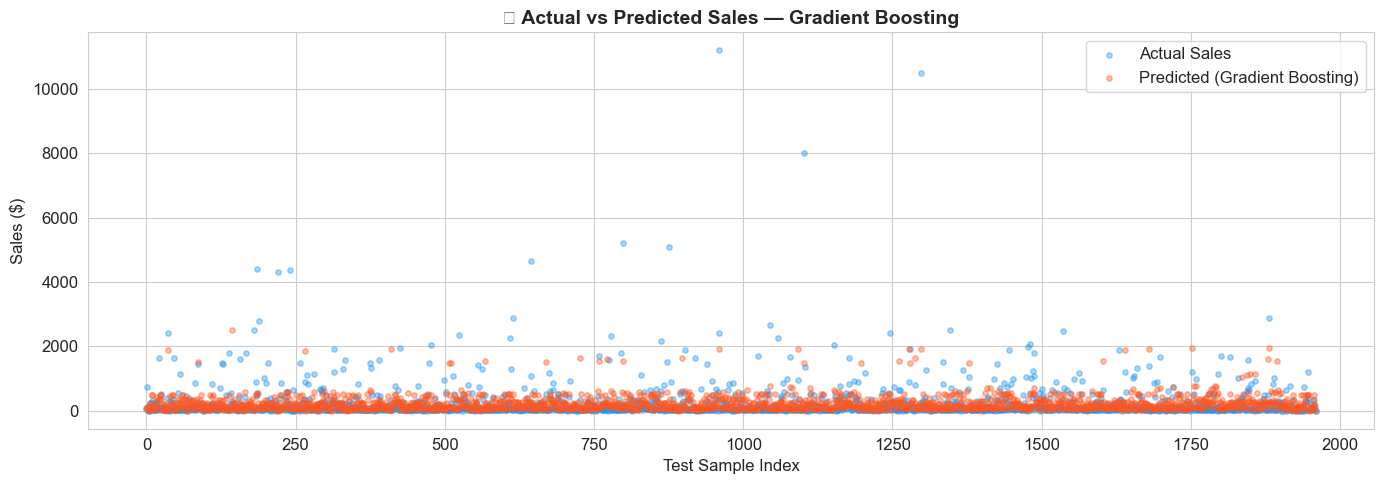

In [22]:
best_model_name = max(results, key=lambda k: results[k]['R2'])
best_preds = results[best_model_name]['Predictions']

print(f' Best Model: {best_model_name}  (R² = {results[best_model_name]["R2"]:.4f})')

plt.figure(figsize=(14, 5))
plt.scatter(range(len(y_test)), y_test.values, alpha=0.4, s=15,
            color='#2196F3', label='Actual Sales')
plt.scatter(range(len(best_preds)), best_preds, alpha=0.4, s=15,
            color='#FF5722', label=f'Predicted ({best_model_name})')
plt.title(f'🎯 Actual vs Predicted Sales — {best_model_name}', fontsize=14, fontweight='bold')
plt.xlabel('Test Sample Index')
plt.ylabel('Sales ($)')
plt.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
# Cell 12 — Feature Importance! 

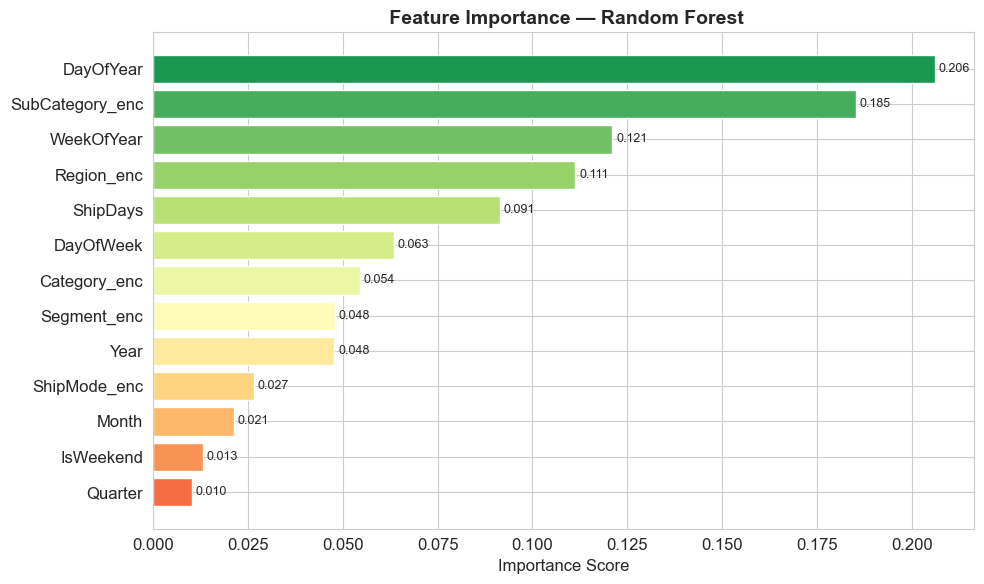

 Feature importance chart saved!


In [24]:
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(importances.index, importances.values,
                color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(importances))))
plt.title(' Feature Importance — Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
for bar, val in zip(bars, importances.values):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Feature importance chart saved!')

In [25]:
# Cell 13 — Forecast Next 6 Months!

In [26]:
monthly_clean = monthly.dropna().copy()

X_ts = monthly_clean[['MonthNum','Month','Year','Lag_1M','Lag_3M','Rolling_3M','Rolling_6M']]
y_ts = monthly_clean['Sales']

lr_ts = LinearRegression()
lr_ts.fit(X_ts, y_ts)

last_row = monthly_clean.iloc[-1]
last_month = last_row['Date']
future_sales_list = list(monthly_clean['Sales'].values)

future_rows = []
for i in range(1, 7):
    future_date = last_month + pd.DateOffset(months=i)
    month_num   = last_row['MonthNum'] + i
    lag1  = future_sales_list[-1]
    lag3  = future_sales_list[-3] if len(future_sales_list) >= 3 else lag1
    roll3 = np.mean(future_sales_list[-3:])
    roll6 = np.mean(future_sales_list[-6:]) if len(future_sales_list) >= 6 else roll3
    row = {'MonthNum': month_num, 'Month': future_date.month, 'Year': future_date.year,
           'Lag_1M': lag1, 'Lag_3M': lag3, 'Rolling_3M': roll3, 'Rolling_6M': roll6,
           'Date': future_date}
    pred = lr_ts.predict(pd.DataFrame([row[c] for c in X_ts.columns],
                                       index=X_ts.columns).T)[0]
    pred = max(pred, 0)
    row['Forecast'] = pred
    future_rows.append(row)
    future_sales_list.append(pred)

forecast_df = pd.DataFrame(future_rows)
print('6-Month Sales Forecast:')
print(forecast_df[['Date','Forecast']].to_string(index=False))

6-Month Sales Forecast:
      Date     Forecast
2019-01-01 67028.054388
2019-02-01 76328.212790
2019-03-01 66562.698118
2019-04-01 70026.290897
2019-05-01 72215.259764
2019-06-01 70556.288048


In [27]:
# Cell 14 Moving Average Time-Series Forecast 

Moving Average Time-Series Forecast:


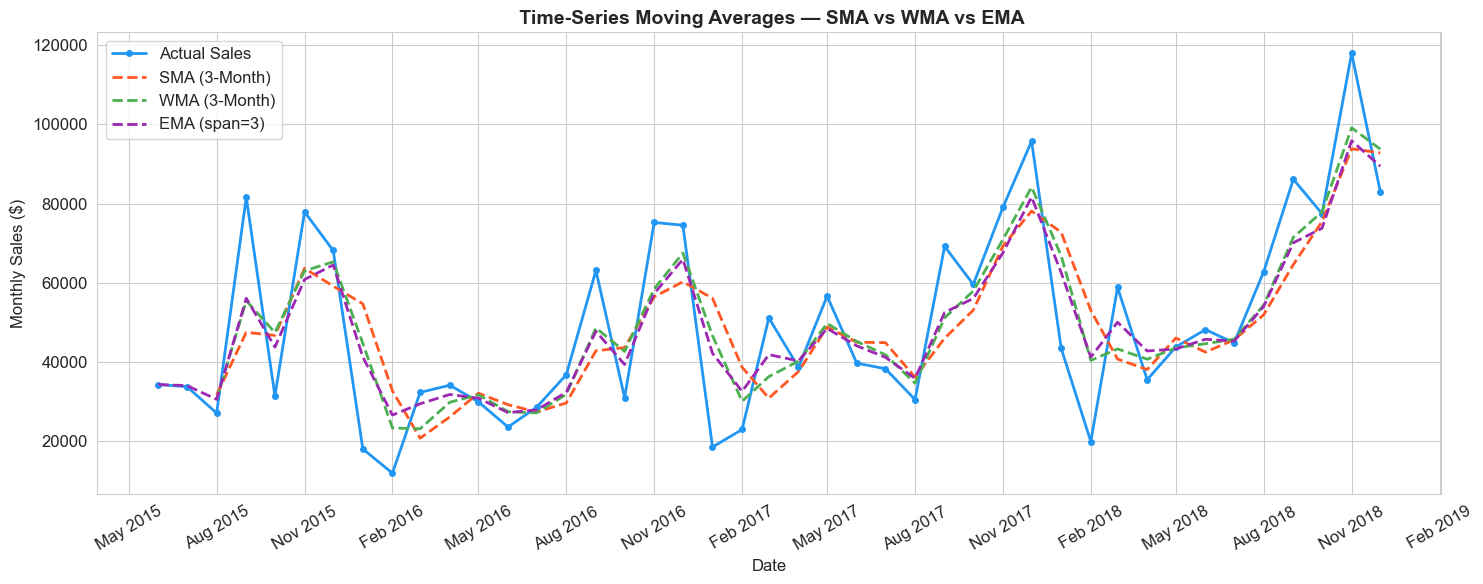

 EMA — MAE: $9,140.23  |  RMSE: $11,756.47
 Moving average chart saved!


In [28]:
# ── Moving Average Time-Series Forecast ──
print('Moving Average Time-Series Forecast:')

# Simple Moving Average (SMA) — 3 month window
monthly_clean['SMA_3'] = monthly_clean['Sales'].rolling(window=3).mean()

# Weighted Moving Average (WMA)
weights = np.array([1, 2, 3])
monthly_clean['WMA_3'] = monthly_clean['Sales'].rolling(window=3).apply(
    lambda x: np.dot(x, weights) / weights.sum(), raw=True)

# Exponential Moving Average (EMA)
monthly_clean['EMA'] = monthly_clean['Sales'].ewm(span=3, adjust=False).mean()

# Plot all moving averages
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(monthly_clean['Date'], monthly_clean['Sales'],
        color='#2196F3', lw=2, marker='o', ms=4, label='Actual Sales')
ax.plot(monthly_clean['Date'], monthly_clean['SMA_3'],
        color='#FF5722', lw=2, ls='--', label='SMA (3-Month)')
ax.plot(monthly_clean['Date'], monthly_clean['WMA_3'],
        color='#4CAF50', lw=2, ls='--', label='WMA (3-Month)')
ax.plot(monthly_clean['Date'], monthly_clean['EMA'],
        color='#9C27B0', lw=2, ls='--', label='EMA (span=3)')
ax.set_title(' Time-Series Moving Averages — SMA vs WMA vs EMA',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Monthly Sales ($)')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('timeseries_moving_averages.png', dpi=150, bbox_inches='tight')
plt.show()

# Error analysis on EMA
ema_valid = monthly_clean.dropna(subset=['EMA'])
mae_ema  = mean_absolute_error(ema_valid['Sales'], ema_valid['EMA'])
rmse_ema = np.sqrt(mean_squared_error(ema_valid['Sales'], ema_valid['EMA']))
print(f' EMA — MAE: ${mae_ema:,.2f}  |  RMSE: ${rmse_ema:,.2f}')
print(' Moving average chart saved!')

In [29]:
# Cell 15 — Forecast Chart! 

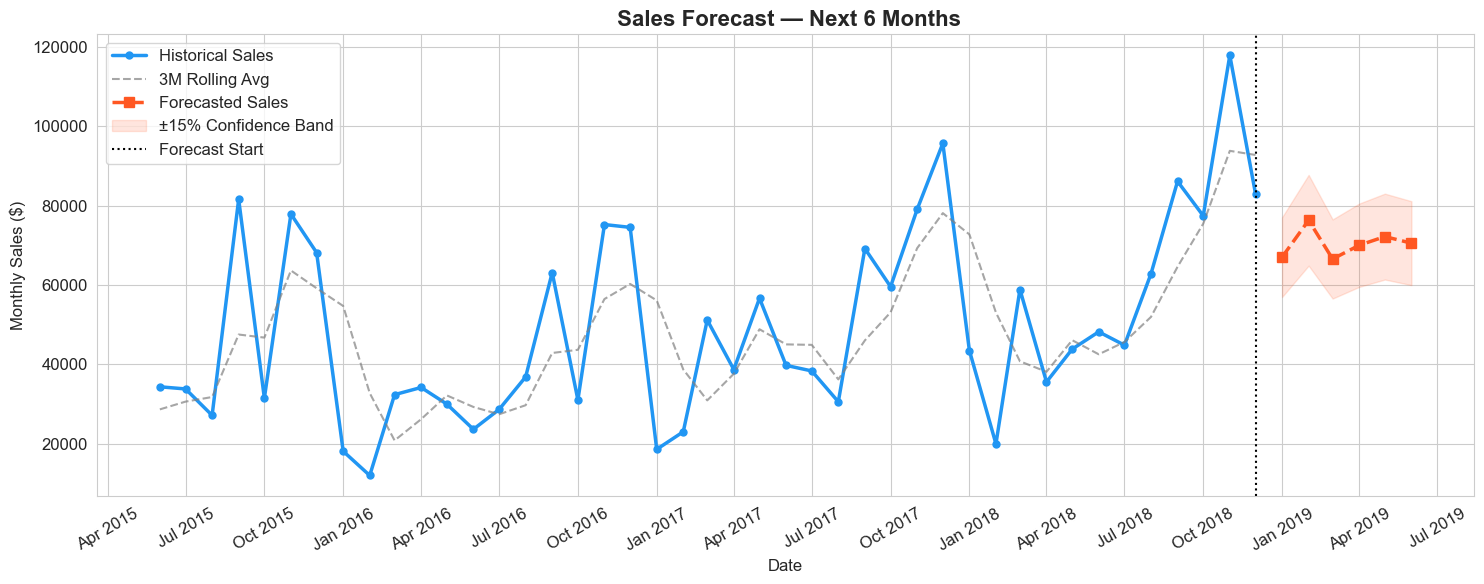

 Forecast chart saved!


In [30]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(monthly_clean['Date'], monthly_clean['Sales'],
        color='#2196F3', lw=2.5, marker='o', ms=5, label='Historical Sales')
ax.plot(monthly_clean['Date'], monthly_clean['Rolling_3M'],
        color='gray', lw=1.5, ls='--', alpha=0.7, label='3M Rolling Avg')
ax.plot(forecast_df['Date'], forecast_df['Forecast'],
        color='#FF5722', lw=2.5, marker='s', ms=7, ls='--', label='Forecasted Sales')
ax.fill_between(forecast_df['Date'],
                forecast_df['Forecast'] * 0.85,
                forecast_df['Forecast'] * 1.15,
                color='#FF5722', alpha=0.15, label='±15% Confidence Band')
ax.axvline(x=monthly_clean['Date'].iloc[-1], color='black', ls=':', lw=1.5, label='Forecast Start')

ax.set_title(' Sales Forecast — Next 6 Months', fontsize=16, fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Monthly Sales ($)')
ax.legend(loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('sales_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Forecast chart saved!')

In [31]:
# Cell 15 — Business Insights Summary! 

In [32]:
print('=' * 55)
print('BUSINESS INSIGHTS SUMMARY')
print('=' * 55)

total_sales  = df['Sales'].sum()
avg_monthly  = monthly['Sales'].mean()
best_month   = monthly.loc[monthly['Sales'].idxmax()]
worst_month  = monthly.loc[monthly['Sales'].idxmin()]
top_category = df.groupby('Category')['Sales'].sum().idxmax()
top_region   = df.groupby('Region')['Sales'].sum().idxmax()
top_segment  = df.groupby('Segment')['Sales'].sum().idxmax()

print(f' Total Revenue          : ${total_sales:>12,.2f}')
print(f' Avg Monthly Sales      : ${avg_monthly:>12,.2f}')
print(f' Best Month             : {best_month["Date"].strftime("%b %Y")} (${best_month["Sales"]:,.2f})')
print(f' Worst Month            : {worst_month["Date"].strftime("%b %Y")} (${worst_month["Sales"]:,.2f})')
print(f' Top Category           : {top_category}')
print(f' Top Region             : {top_region}')
print(f' Top Customer Segment   : {top_segment}')
print()
print(' 6-Month Forecast:')
for _, row in forecast_df.iterrows():
    print(f'   {row["Date"].strftime("%b %Y")}  →  ${row["Forecast"]:>10,.2f}')
print()
print(f' Best Model : {best_model_name}')
print(f'   MAE  : ${results[best_model_name]["MAE"]:,.2f}')
print(f'   RMSE : ${results[best_model_name]["RMSE"]:,.2f}')
print(f'   R²   : {results[best_model_name]["R2"]:.4f}')
print('=' * 55)

BUSINESS INSIGHTS SUMMARY
 Total Revenue          : $2,261,536.78
 Avg Monthly Sales      : $   47,115.35
 Best Month             : Nov 2018 ($117,938.15)
 Worst Month            : Feb 2015 ($4,519.89)
 Top Category           : Technology
 Top Region             : West
 Top Customer Segment   : Consumer

 6-Month Forecast:
   Jan 2019  →  $ 67,028.05
   Feb 2019  →  $ 76,328.21
   Mar 2019  →  $ 66,562.70
   Apr 2019  →  $ 70,026.29
   May 2019  →  $ 72,215.26
   Jun 2019  →  $ 70,556.29

 Best Model : Gradient Boosting
   MAE  : $217.15
   RMSE : $529.81
   R²   : 0.1951
